In [ ]:
from google.colab import files
import pandas as pd

# 1. Trigger the browser file upload prompt
uploaded = files.upload()

# 2. Automatically locate the uploaded filename and read it into a dataframe
file_name = list(uploaded.keys())[0]
df = pd.read_csv(file_name)

print("\n=============================================")
print(f" Successfully uploaded and loaded: {file_name}")
print(f" Dataset contains {df.shape[0]:,} rows and {df.shape[1]} columns.")
print("=============================================")

Saving traffic.csv to traffic.csv

 Successfully uploaded and loaded: traffic.csv
 Dataset contains 226,278 rows and 9 columns.


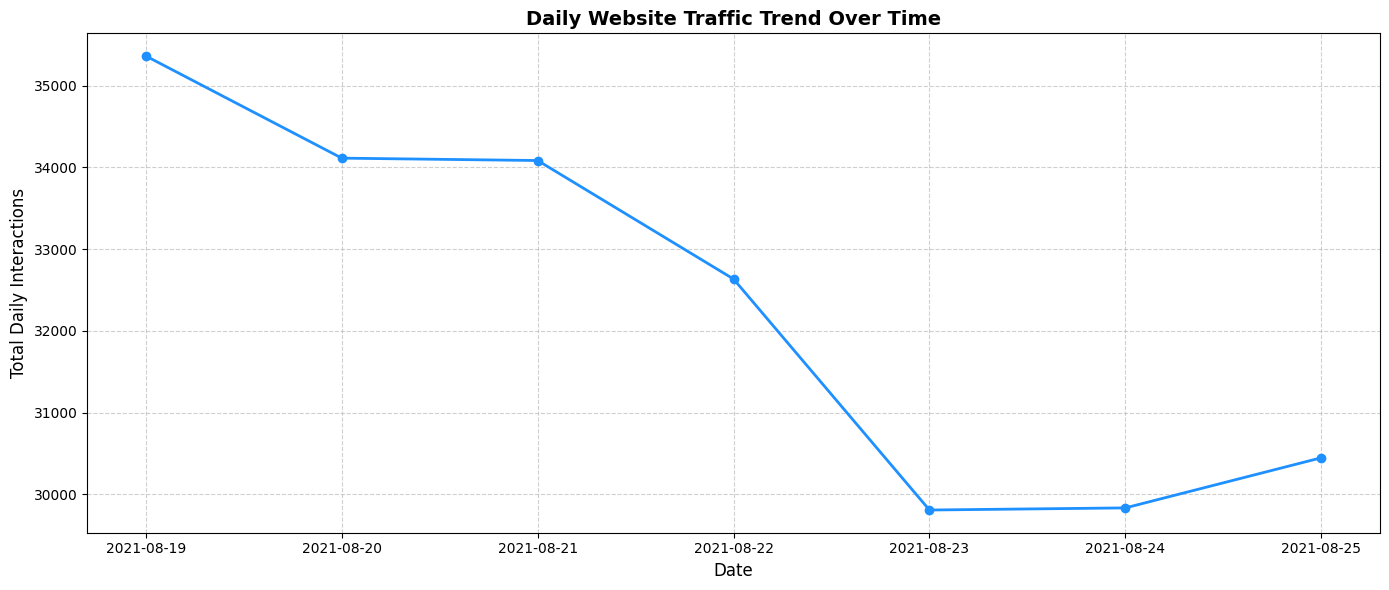

In [ ]:
# 1. Convert the date column to a proper datetime format
df['date'] = pd.to_datetime(df['date'])

# 2. Group traffic by date to find daily trends
daily_traffic = df.groupby('date').size().reset_index(name='total_interactions')

# 3. Plot the timeline trend
plt.figure(figsize=(14, 6))
plt.plot(daily_traffic['date'], daily_traffic['total_interactions'], color='dodgerblue', marker='o', linewidth=2)

plt.title('Daily Website Traffic Trend Over Time', fontsize=14, fontweight='bold')
plt.xlabel('Date', fontsize=12)
plt.ylabel('Total Daily Interactions', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

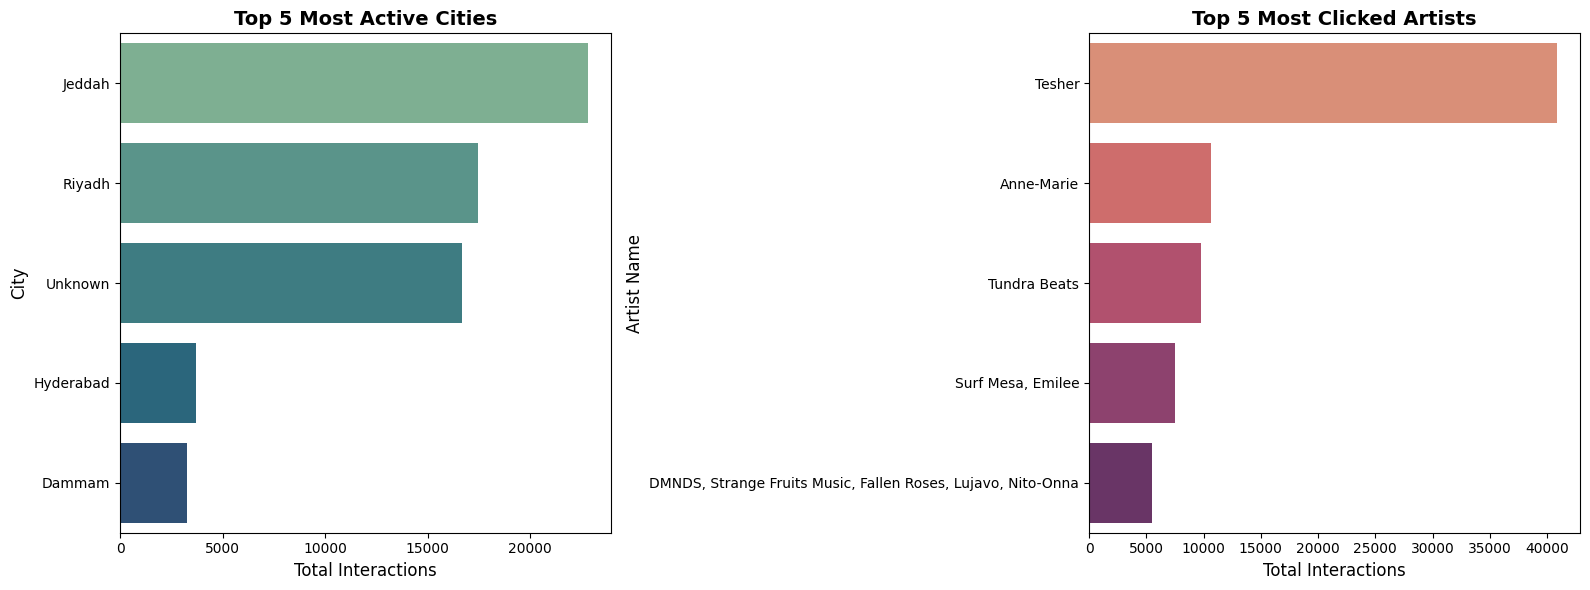

In [ ]:
# Create a figure space for content & geography leaders
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Top 5 Cities by Traffic
top_cities = df['city'].value_counts().head(5).reset_index()
sns.barplot(data=top_cities, x='count', y='city', ax=axes[0], palette='crest', hue='city', legend=False)
axes[0].set_title('Top 5 Most Active Cities', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Total Interactions', fontsize=12)
axes[0].set_ylabel('City', fontsize=12)

# 2. Top 5 Most Popular Artists
top_artists = df['artist'].value_counts().head(5).reset_index()
sns.barplot(data=top_artists, x='count', y='artist', ax=axes[1], palette='flare', hue='artist', legend=False)
axes[1].set_title('Top 5 Most Clicked Artists', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Total Interactions', fontsize=12)
axes[1].set_ylabel('Artist Name', fontsize=12)

plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd

# 1. Ensure the dataset is loaded and dates are formatted properly
df = pd.read_csv('traffic.csv')
df.columns = df.columns.str.strip()
df['date'] = pd.to_datetime(df['date'])

# 2. Re-calculate metrics behind the scenes to avoid any missing variable errors
daily_traffic = df.groupby('date').size().reset_index(name='total_interactions')
event_counts = df['event'].value_counts().reset_index()
top_countries = df['country'].value_counts().head(10).reset_index()
top_cities = df['city'].value_counts().head(5).reset_index()
top_artists = df['artist'].value_counts().head(5).reset_index()

# 3. Export the clean processed dataset
df.to_csv('website_traffic_processed_report.csv', index=False)

# 4. Extract leading metrics safely
most_active_date = daily_traffic.loc[daily_traffic['total_interactions'].idxmax()]
top_event = event_counts.iloc[0]['event']
top_country_name = top_countries.iloc[0]['country']
top_city_name = top_cities.iloc[0]['city']
top_artist_name = top_artists.iloc[0]['artist']

print("==================================================")
print("         EXECUTIVE WEBSITE TRAFFIC REPORT         ")
print("==================================================")
print(f"• Total Data Points Analyzed: {df.shape[0]:,}")
print(f"• Core Engagement Type: {top_event.upper()} ({event_counts.iloc[0]['count']:,} events)")
print(f"• Peak Traffic Date: {most_active_date['date'].strftime('%Y-%m-%d')} ({most_active_date['total_interactions']:,} hits)")
print(f"• #1 Primary Market Country: {top_country_name}")
print(f"• #1 High-Density Traffic City: {top_city_name}")
print(f"• #1 Most Popular Artist: {top_artist_name}")
print("==================================================")
print("File successfully saved as 'website_traffic_processed_report.csv'!")

         EXECUTIVE WEBSITE TRAFFIC REPORT         
• Total Data Points Analyzed: 226,278
• Core Engagement Type: PAGEVIEW (142,015 events)
• Peak Traffic Date: 2021-08-19 (35,361 hits)
• #1 Primary Market Country: Saudi Arabia
• #1 High-Density Traffic City: Jeddah
• #1 Most Popular Artist: Tesher
File successfully saved as 'website_traffic_processed_report.csv'!


In [ ]:
import pandas as pd

# 1. Ensure the dataset is loaded and dates are formatted properly
df = pd.read_csv('traffic.csv')
df.columns = df.columns.str.strip()
df['date'] = pd.to_datetime(df['date'])

# 2. Re-calculate metrics behind the scenes with correct lowercase keys
daily_traffic = df.groupby('date').size().reset_index(name='total_interactions')
event_counts = df['event'].value_counts().reset_index()
top_countries = df['country'].value_counts().head(10).reset_index()
top_cities = df['city'].value_counts().head(5).reset_index()
top_artists = df['artist'].value_counts().head(5).reset_index()

# 3. Export the clean processed dataset
df.to_csv('website_traffic_processed_report.csv', index=False)

# 4. Extract leading metrics safely (using exact lowercase keys from value_counts)
most_active_date = daily_traffic.loc[daily_traffic['total_interactions'].idxmax()]
top_event = event_counts.iloc[0]['event']
top_event_count = event_counts.iloc[0]['count']
top_country_name = top_countries.iloc[0]['country']
top_city_name = top_cities.iloc[0]['city']
top_artist_name = top_artists.iloc[0]['artist']

print("==================================================")
print("         EXECUTIVE WEBSITE TRAFFIC REPORT         ")
print("==================================================")
print(f"• Total Data Points Analyzed: {df.shape[0]:,}")
print(f"• Core Engagement Type: {top_event.upper()} ({top_event_count:,} events)")
print(f"• Peak Traffic Date: {most_active_date['date'].strftime('%Y-%m-%d')} ({most_active_date['total_interactions']:,} hits)")
print(f"• #1 Primary Market Country: {top_country_name}")
print(f"• #1 High-Density Traffic City: {top_city_name}")
print(f"• #1 Most Popular Artist: {top_artist_name}")
print("==================================================")
print("File successfully saved as 'website_traffic_processed_report.csv'!")

         EXECUTIVE WEBSITE TRAFFIC REPORT         
• Total Data Points Analyzed: 226,278
• Core Engagement Type: PAGEVIEW (142,015 events)
• Peak Traffic Date: 2021-08-19 (35,361 hits)
• #1 Primary Market Country: Saudi Arabia
• #1 High-Density Traffic City: Jeddah
• #1 Most Popular Artist: Tesher
File successfully saved as 'website_traffic_processed_report.csv'!
